In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv("../data/landslide_dataset.csv")

# Display the first five rows
df.head()

,Rainfall_mm,Slope_Angle,Soil_Saturation,Vegetation_Cover,Earthquake_Activity,Proximity_to_Water,Landslide,Soil_Type_Gravel,Soil_Type_Sand,Soil_Type_Silt
0,206.181018,58.275001,0.892798,0.339463,4.390047,0.099975,1,0,0,0
1,218.887334,36.679801,0.657147,0.360355,4.141029,0.832443,1,0,0,1
2,181.850867,31.363874,0.673362,0.221697,5.311891,0.023062,1,0,0,1
3,228.716199,38.995134,0.618666,0.489502,4.581928,0.785176,1,0,0,1
4,179.951067,42.998205,0.836966,0.118580,5.518862,0.450499,1,0,0,0


In [3]:
# Dataset dimensions
print("Dataset shape:", df.shape)

# Column names
print("\nColumns:")
print(df.columns.tolist())

# Data types
print("\nData types:")
print(df.dtypes)

# Missing values
print("\nMissing values:")
print(df.isnull().sum())

# Duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Target distribution
print("\nLandslide distribution:")
print(df["Landslide"].value_counts())

Dataset shape: (2000, 10)

Columns:
['Rainfall_mm', 'Slope_Angle', 'Soil_Saturation', 'Vegetation_Cover', 'Earthquake_Activity', 'Proximity_to_Water', 'Landslide', 'Soil_Type_Gravel', 'Soil_Type_Sand', 'Soil_Type_Silt']

Data types:
Rainfall_mm            float64
Slope_Angle            float64
Soil_Saturation        float64
Vegetation_Cover       float64
Earthquake_Activity    float64
Proximity_to_Water     float64
Landslide                int64
Soil_Type_Gravel         int64
Soil_Type_Sand           int64
Soil_Type_Silt           int64
dtype: object

Missing values:
Rainfall_mm            0
Slope_Angle            0
Soil_Saturation        0
Vegetation_Cover       0
Earthquake_Activity    0
Proximity_to_Water     0
Landslide              0
Soil_Type_Gravel       0
Soil_Type_Sand         0
Soil_Type_Silt         0
dtype: int64

Duplicate rows: 0

Landslide distribution:
Landslide
1    1000
0    1000
Name: count, dtype: int64


In [4]:

# Compare average feature values for each class
feature_comparison = df.groupby("Landslide").mean(numeric_only=True).T

print("Average feature values for each Landslide class:")
display(feature_comparison.round(3))

Average feature values for each Landslide class:


Landslide,0,1
Rainfall_mm,127.111,226.266
Slope_Angle,17.717,42.253
Soil_Saturation,0.282,0.798
Vegetation_Cover,0.748,0.298
Earthquake_Activity,1.974,5.235
Proximity_to_Water,1.503,0.501
Soil_Type_Gravel,0.517,0.000
Soil_Type_Sand,0.483,0.000
Soil_Type_Silt,0.000,0.522


In [5]:

# Examine the relationship between soil indicators and the target

soil_columns = [
    "Soil_Type_Gravel",
    "Soil_Type_Sand",
    "Soil_Type_Silt"
]

for column in soil_columns:
    print(f"\n{column}")
    display(pd.crosstab(df[column], df["Landslide"], margins=True))



Soil_Type_Gravel


Landslide,0,1,All
Soil_Type_Gravel,,,
0,483,1000,1483
1,517,0,517
All,1000,1000,2000



Soil_Type_Sand


Landslide,0,1,All
Soil_Type_Sand,,,
0,517,1000,1517
1,483,0,483
All,1000,1000,2000



Soil_Type_Silt


Landslide,0,1,All
Soil_Type_Silt,,,
0,1000,478,1478
1,0,522,522
All,1000,1000,2000


In [6]:

# Compare rainfall statistics for both classes

display(
    df.groupby("Landslide")["Rainfall_mm"]
      .describe()
      .round(2)
)

# Find the overlapping rainfall range
rainfall_0 = df.loc[df["Landslide"] == 0, "Rainfall_mm"]
rainfall_1 = df.loc[df["Landslide"] == 1, "Rainfall_mm"]

overlap_start = max(rainfall_0.min(), rainfall_1.min())
overlap_end = min(rainfall_0.max(), rainfall_1.max())

print("\nRainfall range for class 0:",
      rainfall_0.min(), "to", rainfall_0.max())

print("Rainfall range for class 1:",
      rainfall_1.min(), "to", rainfall_1.max())

if overlap_start <= overlap_end:
    print("The rainfall ranges overlap from",
          round(overlap_start, 2), "to",
          round(overlap_end, 2), "mm")
else:
    print("The rainfall ranges do not overlap.")

,count,mean,std,min,25%,50%,75%,max
Landslide,,,,,,,,
0,1000.0,127.11,43.42,50.04,90.53,128.35,165.08,199.85
1,1000.0,226.27,42.87,150.20,189.12,228.77,262.23,299.92



Rainfall range for class 0: 50.0361507028 to 199.8514192503
Rainfall range for class 1: 150.2019406435 to 299.919102159
The rainfall ranges overlap from 150.2 to 199.85 mm


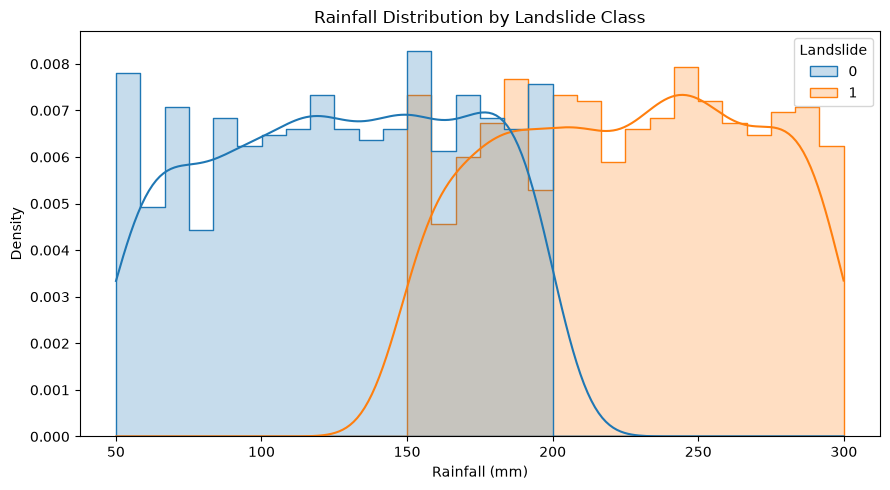

In [7]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="Rainfall_mm",
    hue="Landslide",
    bins=30,
    kde=True,
    element="step",
    stat="density",
    common_norm=False
)

plt.title("Rainfall Distribution by Landslide Class")
plt.xlabel("Rainfall (mm)")
plt.ylabel("Density")
plt.tight_layout()
plt.show()

In [8]:
soil_columns = [
    "Soil_Type_Gravel",
    "Soil_Type_Sand",
    "Soil_Type_Silt"
]

# Count active soil indicators in each observation
df["Soil_Indicator_Count"] = df[soil_columns].sum(axis=1)

print("Number of active soil indicators:")
print(df["Soil_Indicator_Count"].value_counts().sort_index())

# Display soil combinations for each target class
print("\nSoil combinations by landslide class:")

display(
    df.groupby(
        soil_columns + ["Landslide"]
    ).size().reset_index(name="Count")
)

Number of active soil indicators:
Soil_Indicator_Count
0     478
1    1522
Name: count, dtype: int64

Soil combinations by landslide class:


,Soil_Type_Gravel,Soil_Type_Sand,Soil_Type_Silt,Landslide,Count
0,0,0,0,1,478
1,0,0,1,1,522
2,0,1,0,0,483
3,1,0,0,0,517


In [9]:
# Step 1: Prepare features and target

from sklearn.model_selection import train_test_split

# Input features
X = df.drop("Landslide", axis=1)

# Target variable
y = df["Landslide"]

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display dataset sizes
print("Total records:", len(df))
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Total records: 2000
Training records: 1600
Testing records: 400

Training target distribution:
Landslide
1    800
0    800
Name: count, dtype: int64

Testing target distribution:
Landslide
0    200
1    200
Name: count, dtype: int64


In [10]:
# Step 2: Train both machine learning models

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Model 1: Logistic Regression
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(random_state=42, max_iter=1000))
])

# Model 2: Random Forest
random_forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    max_depth=None
)

# Train Logistic Regression
logistic_model.fit(X_train, y_train)

# Train Random Forest
random_forest_model.fit(X_train, y_train)

print("Logistic Regression training completed!")
print("Random Forest training completed!")

Logistic Regression training completed!
Random Forest training completed!


In [11]:

# Step 3: Evaluate both trained models

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Generate predictions
lr_predictions = logistic_model.predict(X_test)
rf_predictions = random_forest_model.predict(X_test)

# Calculate prediction probabilities for ROC-AUC
lr_probabilities = logistic_model.predict_proba(X_test)[:, 1]
rf_probabilities = random_forest_model.predict_proba(X_test)[:, 1]

# Compare model performance
results = []

models = {
    "Logistic Regression": (lr_predictions, lr_probabilities),
    "Random Forest": (rf_predictions, rf_probabilities)
}

for model_name, (predictions, probabilities) in models.items():
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-Score": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

results_df = pd.DataFrame(results)

print("MODEL COMPARISON")
display(results_df.round(4))

print("\nLOGISTIC REGRESSION CLASSIFICATION REPORT")
print(classification_report(
    y_test, lr_predictions, zero_division=0
))

print("\nRANDOM FOREST CLASSIFICATION REPORT")
print(classification_report(
    y_test, rf_predictions, zero_division=0
))


MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,1.0,1.0,1.0,1.0,1.0
1,Random Forest,1.0,1.0,1.0,1.0,1.0



LOGISTIC REGRESSION CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       200
           1       1.00      1.00      1.00       200

    accuracy                           1.00       400
   macro avg       1.00      1.00      1.00       400
weighted avg       1.00      1.00      1.00       400


RANDOM FOREST CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       200
           1       1.00      1.00      1.00       200

    accuracy                           1.00       400
   macro avg       1.00      1.00      1.00       400
weighted avg       1.00      1.00      1.00       400



In [12]:
# Experiment 2: Remove soil indicator columns

soil_columns = [
    "Soil_Type_Gravel",
    "Soil_Type_Sand",
    "Soil_Type_Silt"
]

# Keep the six remaining features
X_reduced = X.drop(columns=soil_columns)

# Split the reduced dataset
X_train_reduced, X_test_reduced, y_train_reduced, y_test_reduced = (
    train_test_split(
        X_reduced,
        y,
        test_size=0.20,
        random_state=42,
        stratify=y
    )
)

print("Original number of features:", X.shape[1])
print("Reduced number of features:", X_reduced.shape[1])

print("\nFeatures used in Experiment 2:")
print(X_reduced.columns.tolist())

print("\nTraining records:", len(X_train_reduced))
print("Testing records:", len(X_test_reduced))

Original number of features: 10
Reduced number of features: 7

Features used in Experiment 2:
['Rainfall_mm', 'Slope_Angle', 'Soil_Saturation', 'Vegetation_Cover', 'Earthquake_Activity', 'Proximity_to_Water', 'Soil_Indicator_Count']

Training records: 1600
Testing records: 400


In [13]:
# Experiment 2: Remove all soil-related indicator features

soil_columns = [
    "Soil_Type_Gravel",
    "Soil_Type_Sand",
    "Soil_Type_Silt",
    "Soil_Indicator_Count"
]

# Remove all four soil-related columns
X_reduced = X.drop(columns=soil_columns)

# Split the reduced dataset
X_train_reduced, X_test_reduced, y_train_reduced, y_test_reduced = (
    train_test_split(
        X_reduced,
        y,
        test_size=0.20,
        random_state=42,
        stratify=y
    )
)

print("Original number of features:", X.shape[1])
print("Reduced number of features:", X_reduced.shape[1])

print("\nFeatures used:")
print(X_reduced.columns.tolist())

print("\nTraining records:", len(X_train_reduced))
print("Testing records:", len(X_test_reduced))

Original number of features: 10
Reduced number of features: 6

Features used:
['Rainfall_mm', 'Slope_Angle', 'Soil_Saturation', 'Vegetation_Cover', 'Earthquake_Activity', 'Proximity_to_Water']

Training records: 1600
Testing records: 400


In [14]:
# Experiment 2: Train Logistic Regression and Random Forest
# using only six features

# Logistic Regression
logistic_model_reduced = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        random_state=42,
        max_iter=1000
    ))
])

logistic_model_reduced.fit(
    X_train_reduced,
    y_train_reduced
)

# Random Forest
random_forest_model_reduced = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

random_forest_model_reduced.fit(
    X_train_reduced,
    y_train_reduced
)

print("Reduced-feature Logistic Regression trained!")
print("Reduced-feature Random Forest trained!")

Reduced-feature Logistic Regression trained!
Reduced-feature Random Forest trained!


In [15]:
# Generate predictions
lr_reduced_predictions = logistic_model_reduced.predict(
    X_test_reduced
)

rf_reduced_predictions = random_forest_model_reduced.predict(
    X_test_reduced
)

# Generate probabilities
lr_reduced_probabilities = logistic_model_reduced.predict_proba(
    X_test_reduced
)[:, 1]

rf_reduced_probabilities = random_forest_model_reduced.predict_proba(
    X_test_reduced
)[:, 1]

# Calculate evaluation metrics
reduced_results = []

reduced_models = {
    "Logistic Regression": (
        lr_reduced_predictions,
        lr_reduced_probabilities
    ),
    "Random Forest": (
        rf_reduced_predictions,
        rf_reduced_probabilities
    )
}

for model_name, (predictions, probabilities) in reduced_models.items():
    reduced_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(
            y_test_reduced, predictions
        ),
        "Precision": precision_score(
            y_test_reduced, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test_reduced, predictions, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test_reduced, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_test_reduced, probabilities
        )
    })

reduced_results_df = pd.DataFrame(reduced_results)

print("MODEL COMPARISON WITHOUT SOIL INDICATORS")
display(reduced_results_df.round(4))

MODEL COMPARISON WITHOUT SOIL INDICATORS


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,1.0,1.0,1.0,1.0,1.0
1,Random Forest,1.0,1.0,1.0,1.0,1.0


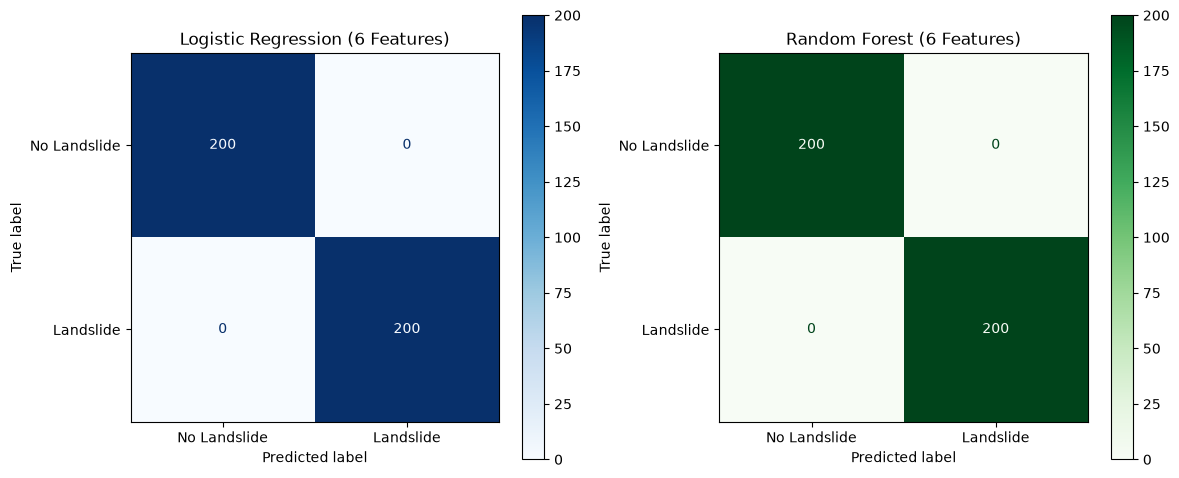

In [16]:
#Examine the confusion matrices

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Logistic Regression
ConfusionMatrixDisplay.from_predictions(
    y_test_reduced,
    lr_reduced_predictions,
    display_labels=["No Landslide", "Landslide"],
    cmap="Blues",
    ax=axes[0]
)

axes[0].set_title("Logistic Regression (6 Features)")

# Random Forest
ConfusionMatrixDisplay.from_predictions(
    y_test_reduced,
    rf_reduced_predictions,
    display_labels=["No Landslide", "Landslide"],
    cmap="Greens",
    ax=axes[1]
)

axes[1].set_title("Random Forest (6 Features)")

plt.tight_layout()
plt.show()

In [17]:
# Compare feature statistics for each target class

feature_comparison = df.groupby("Landslide")[
    [
        "Rainfall_mm",
        "Slope_Angle",
        "Soil_Saturation",
        "Vegetation_Cover",
        "Earthquake_Activity",
        "Proximity_to_Water"
    ]
].agg(["mean", "min", "max", "std"])

display(feature_comparison.round(3))

Rainfall_mm                          Slope_Angle                  \
                 mean      min      max    std        mean     min     max   
Landslide                                                                    
0             127.111   50.036  199.851  43.42      17.717   5.004  29.983   
1             226.266  150.202  299.919  42.87      42.253  25.039  59.967   

                  Soil_Saturation         ... Vegetation_Cover         \
              std            mean    min  ...              max    std   
Landslide                                 ...                           
0           7.355           0.282  0.001  ...              1.0  0.146   
1          10.268           0.798  0.600  ...              0.5  0.113   

          Earthquake_Activity                      Proximity_to_Water         \
                         mean    min    max    std               mean    min   
Landslide                                                                      
0                       1.974  0.002  3.993  1.163              1.503  1.000   
1                       5.235  4.000  6.499  0.719              0.501  0.001   

                         
             max    std  
Landslide                
0          2.000  0.288  
1          0.999  0.296  

[2 rows x 24 columns]

In [18]:
# Inspect minimum and maximum values for each target class

features_to_check = [
    "Rainfall_mm",
    "Slope_Angle",
    "Soil_Saturation",
    "Vegetation_Cover",
    "Earthquake_Activity",
    "Proximity_to_Water"
]

for feature in features_to_check:
    print(f"\n{feature}")

    print(
        df.groupby("Landslide")[feature]
        .agg(["min", "max", "mean", "std"])
        .round(3)
    )


Rainfall_mm
               min      max     mean    std
Landslide                                  
0           50.036  199.851  127.111  43.42
1          150.202  299.919  226.266  42.87

Slope_Angle
              min     max    mean     std
Landslide                                
0           5.004  29.983  17.717   7.355
1          25.039  59.967  42.253  10.268

Soil_Saturation
             min    max   mean    std
Landslide                            
0          0.001  0.600  0.282  0.170
1          0.600  0.999  0.798  0.114

Vegetation_Cover
             min  max   mean    std
Landslide                          
0          0.501  1.0  0.748  0.146
1          0.100  0.5  0.298  0.113

Earthquake_Activity
             min    max   mean    std
Landslide                            
0          0.002  3.993  1.974  1.163
1          4.000  6.499  5.235  0.719

Proximity_to_Water
             min    max   mean    std
Landslide                            
0          1.000  2.000  1.503

In [19]:
# Diagnostic experiment: Train models using one feature at a time

from sklearn.metrics import accuracy_score
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

diagnostic_features = [
    "Rainfall_mm",
    "Slope_Angle",
    "Soil_Saturation",
    "Vegetation_Cover",
    "Earthquake_Activity",
    "Proximity_to_Water"
]

diagnostic_results = []

for feature in diagnostic_features:

    # Select one feature
    X_single = df[[feature]]

    # Split the data consistently
    X_train_single, X_test_single, y_train_single, y_test_single = (
        train_test_split(
            X_single,
            y,
            test_size=0.20,
            random_state=42,
            stratify=y
        )
    )

    # Train Logistic Regression
    single_model = Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            random_state=42,
            max_iter=1000
        ))
    ])

    single_model.fit(X_train_single, y_train_single)

    # Evaluate
    predictions = single_model.predict(X_test_single)

    diagnostic_results.append({
        "Feature": feature,
        "Accuracy": accuracy_score(y_test_single, predictions)
    })

diagnostic_df = pd.DataFrame(diagnostic_results)

display(
    diagnostic_df.sort_values(
        by="Accuracy",
        ascending=False
    ).round(4)
)

,Feature,Accuracy
5,Proximity_to_Water,1.0000
3,Vegetation_Cover,0.9975
2,Soil_Saturation,0.9925
4,Earthquake_Activity,0.9925
1,Slope_Angle,0.9200
0,Rainfall_mm,0.8375


In [20]:
# Final comparison of Logistic Regression and Random Forest

final_comparison = pd.DataFrame([
    {
        "Experiment": "All Features",
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(y_test, lr_predictions),
        "Precision": precision_score(y_test, lr_predictions),
        "Recall": recall_score(y_test, lr_predictions),
        "F1-Score": f1_score(y_test, lr_predictions),
        "ROC-AUC": roc_auc_score(y_test, lr_probabilities)
    },
    {
        "Experiment": "All Features",
        "Model": "Random Forest",
        "Accuracy": accuracy_score(y_test, rf_predictions),
        "Precision": precision_score(y_test, rf_predictions),
        "Recall": recall_score(y_test, rf_predictions),
        "F1-Score": f1_score(y_test, rf_predictions),
        "ROC-AUC": roc_auc_score(y_test, rf_probabilities)
    },
    {
        "Experiment": "Six Features",
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(y_test_reduced, lr_reduced_predictions),
        "Precision": precision_score(y_test_reduced, lr_reduced_predictions),
        "Recall": recall_score(y_test_reduced, lr_reduced_predictions),
        "F1-Score": f1_score(y_test_reduced, lr_reduced_predictions),
        "ROC-AUC": roc_auc_score(y_test_reduced, lr_reduced_probabilities)
    },
    {
        "Experiment": "Six Features",
        "Model": "Random Forest",
        "Accuracy": accuracy_score(y_test_reduced, rf_reduced_predictions),
        "Precision": precision_score(y_test_reduced, rf_reduced_predictions),
        "Recall": recall_score(y_test_reduced, rf_reduced_predictions),
        "F1-Score": f1_score(y_test_reduced, rf_reduced_predictions),
        "ROC-AUC": roc_auc_score(y_test_reduced, rf_reduced_probabilities)
    }
])

display(final_comparison.round(4))

,Experiment,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,All Features,Logistic Regression,1.0,1.0,1.0,1.0,1.0
1,All Features,Random Forest,1.0,1.0,1.0,1.0,1.0
2,Six Features,Logistic Regression,1.0,1.0,1.0,1.0,1.0
3,Six Features,Random Forest,1.0,1.0,1.0,1.0,1.0


In [21]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
import pandas as pd

# Use the six selected features
X_cv = X_reduced
y_cv = y

# Create 5-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Define the models
models_cv = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            random_state=42,
            max_iter=1000
        ))
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
}

# Evaluate each model
cv_results = []

for model_name, model in models_cv.items():

    scores = cross_validate(
        model,
        X_cv,
        y_cv,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "precision": "precision",
            "recall": "recall",
            "f1": "f1",
            "roc_auc": "roc_auc"
        }
    )

    cv_results.append({
        "Model": model_name,
        "Mean Accuracy": scores["test_accuracy"].mean(),
        "Mean Precision": scores["test_precision"].mean(),
        "Mean Recall": scores["test_recall"].mean(),
        "Mean F1-Score": scores["test_f1"].mean(),
        "Mean ROC-AUC": scores["test_roc_auc"].mean()
    })

# Display the results
cv_results_df = pd.DataFrame(cv_results)

display(cv_results_df.round(4))

,Model,Mean Accuracy,Mean Precision,Mean Recall,Mean F1-Score,Mean ROC-AUC
0,Logistic Regression,1.0,1.0,1.0,1.0,1.0
1,Random Forest,1.0,1.0,1.0,1.0,1.0


In [22]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
import pandas as pd

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=1000, random_state=42))
    ]),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
}

fold_results = []

for name, model in models.items():
    scores = cross_validate(
        model,
        X_reduced,
        y,
        cv=cv,
        scoring=["accuracy", "precision", "recall", "f1", "roc_auc"]
    )

    for fold in range(5):
        fold_results.append({
            "Model": name,
            "Fold": fold + 1,
            "Accuracy": scores["test_accuracy"][fold],
            "Precision": scores["test_precision"][fold],
            "Recall": scores["test_recall"][fold],
            "F1-Score": scores["test_f1"][fold],
            "ROC-AUC": scores["test_roc_auc"][fold]
        })

fold_results_df = pd.DataFrame(fold_results)

display(fold_results_df.round(4))

,Model,Fold,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,1,1.0,1.0,1.0,1.0,1.0
1,Logistic Regression,2,1.0,1.0,1.0,1.0,1.0
2,Logistic Regression,3,1.0,1.0,1.0,1.0,1.0
3,Logistic Regression,4,1.0,1.0,1.0,1.0,1.0
4,Logistic Regression,5,1.0,1.0,1.0,1.0,1.0
5,Random Forest,1,1.0,1.0,1.0,1.0,1.0
6,Random Forest,2,1.0,1.0,1.0,1.0,1.0
7,Random Forest,3,1.0,1.0,1.0,1.0,1.0
8,Random Forest,4,1.0,1.0,1.0,1.0,1.0
9,Random Forest,5,1.0,1.0,1.0,1.0,1.0


In [23]:
import pandas as pd

# Create a dataframe using the six selected features and target
analysis_df = X_reduced.copy()
analysis_df["Landslide"] = y

# Compare feature averages for each target class
print("Feature averages for each Landslide class:")
display(analysis_df.groupby("Landslide").mean().round(4))

# Calculate correlations with the target
print("Feature correlation with Landslide:")
correlations = (
    analysis_df.corr(numeric_only=True)["Landslide"]
    .drop("Landslide")
    .sort_values(key=abs, ascending=False)
)

display(correlations.to_frame(name="Correlation").round(4))

Feature averages for each Landslide class:


,Rainfall_mm,Slope_Angle,Soil_Saturation,Vegetation_Cover,Earthquake_Activity,Proximity_to_Water
Landslide,,,,,,
0,127.1113,17.7174,0.2825,0.7481,1.9742,1.5029
1,226.2656,42.2534,0.7982,0.2976,5.2353,0.5008


Feature correlation with Landslide:


,Correlation
Soil_Saturation,0.8723
Vegetation_Cover,-0.8653
Proximity_to_Water,-0.8641
Earthquake_Activity,0.8602
Slope_Angle,0.8086
Rainfall_mm,0.7545


In [24]:
# Compare minimum and maximum values for each class

for feature in X_reduced.columns:
    print(f"\nFeature: {feature}")

    for class_value in sorted(y.unique()):
        values = X_reduced.loc[y == class_value, feature]

        print(
            f"Landslide = {class_value}: "
            f"Min = {values.min():.4f}, "
            f"Max = {values.max():.4f}, "
            f"Mean = {values.mean():.4f}"
        )


Feature: Rainfall_mm
Landslide = 0: Min = 50.0362, Max = 199.8514, Mean = 127.1113
Landslide = 1: Min = 150.2019, Max = 299.9191, Mean = 226.2656

Feature: Slope_Angle
Landslide = 0: Min = 5.0039, Max = 29.9829, Mean = 17.7174
Landslide = 1: Min = 25.0392, Max = 59.9667, Mean = 42.2534

Feature: Soil_Saturation
Landslide = 0: Min = 0.0007, Max = 0.5997, Mean = 0.2825
Landslide = 1: Min = 0.6001, Max = 0.9988, Mean = 0.7982

Feature: Vegetation_Cover
Landslide = 0: Min = 0.5006, Max = 0.9998, Mean = 0.7481
Landslide = 1: Min = 0.1000, Max = 0.4997, Mean = 0.2976

Feature: Earthquake_Activity
Landslide = 0: Min = 0.0016, Max = 3.9928, Mean = 1.9742
Landslide = 1: Min = 4.0001, Max = 6.4987, Mean = 5.2353

Feature: Proximity_to_Water
Landslide = 0: Min = 1.0002, Max = 1.9996, Mean = 1.5029
Landslide = 1: Min = 0.0007, Max = 0.9993, Mean = 0.5008


In [25]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import pandas as pd

feature_results = []

for feature in X_reduced.columns:

    # Select only one feature
    X_single = X_reduced[[feature]]

    # Split the data
    X_train_single, X_test_single, y_train_single, y_test_single = (
        train_test_split(
            X_single,
            y,
            test_size=0.20,
            random_state=42,
            stratify=y
        )
    )

    # Create and train the model
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=1000))
    ])

    model.fit(X_train_single, y_train_single)

    # Predict and evaluate
    predictions = model.predict(X_test_single)
    accuracy = accuracy_score(y_test_single, predictions)

    feature_results.append({
        "Feature": feature,
        "Accuracy": accuracy
    })

# Display results from highest to lowest accuracy
feature_results_df = pd.DataFrame(feature_results)
feature_results_df = feature_results_df.sort_values(
    by="Accuracy",
    ascending=False
)

display(feature_results_df.round(4))

,Feature,Accuracy
5,Proximity_to_Water,1.0000
3,Vegetation_Cover,0.9975
2,Soil_Saturation,0.9925
4,Earthquake_Activity,0.9925
1,Slope_Angle,0.9200
0,Rainfall_mm,0.8375


In [ ]:
# Examine how soil types relate to the target

soil_columns = [
    "Soil_Type_Gravel",
    "Soil_Type_Sand",
    "Soil_Type_Silt"
]

for column in soil_columns:
    print(f"\n{column}")

    display(
        df.groupby(column)["Landslide"]
          .value_counts()
          .unstack(fill_value=0)
    )